<a href="https://colab.research.google.com/github/JeyssonP92/Proyectos-Python-y-QA/blob/main/pipeline%20de%20Data%20QA%20con%20Pytest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pytest ipytest seaborn matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 90.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ipytest]


In [2]:
import ipytest
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#motor de pruebas y diseño visual
ipytest.autoconfig()
sns.set_theme(style="whitegrid")

Exploracion y monitoreo visual del dataset

In [3]:
URL_DATASET = "https://raw.githubusercontent.com/curran/data/gh-pages/superstoreSales/superstoreSales.csv"

print("descargando dataset")
df = pd.read_csv(URL_DATASET, encoding="latin1")

print("\nREPORTES DE AUDITORÍA INICIAL (DATA QA)")
print("\nInformacion del dataset")
df.info()
print(f"\nTotal de registros cargados: {len(df)}")

filas_duplicadas = df.duplicated().sum()
print(f"\nFilas duplicadas detectadas: {filas_duplicadas}")

casillas_vacias_sales = df["Sales"].isna().sum()
print(f"\nCasillas vacias en la columna Sales: {casillas_vacias_sales}")

casillas_vacias_quantity = df["Order Quantity"].isna().sum()
print(f"\nCasillas vacias en la columna Quantity: {casillas_vacias_quantity}")

descargando dataset

REPORTES DE AUDITORÍA INICIAL (DATA QA)

Informacion del dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8399 entries, 0 to 8398
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Row ID                8399 non-null   int64  
 1   Order ID              8399 non-null   int64  
 2   Order Date            8399 non-null   object 
 3   Order Priority        8399 non-null   object 
 4   Order Quantity        8399 non-null   int64  
 5   Sales                 8399 non-null   float64
 6   Discount              8399 non-null   float64
 7   Ship Mode             8399 non-null   object 
 8   Profit                8399 non-null   float64
 9   Unit Price            8399 non-null   float64
 10  Shipping Cost         8399 non-null   float64
 11  Customer Name         8399 non-null   object 
 12  Province              8399 non-null   object 
 13  Region                8399 non-null  

LIMPIEZA Y TRANSFORMACIÓN DE DATOS


In [17]:
print("Ejecutando limpieza profunda con Pandas")
df_limpio = df.drop_duplicates().copy() #Se eliminan las filas repetidas y se crea una tabla totalmente independiente

if "Sales" in df_limpio.columns:
  df_limpio['Sales'] = df_limpio['Sales'].fillna(df_limpio['Sales'].mean())

if "Order Quantity" in df_limpio.columns:
  df_limpio['Order Quantity'] = df_limpio['Order Quantity'].fillna(1)

print("\nLimpieza del dataset completa")





Ejecutando limpieza profunda con Pandas

Limpieza del dataset completa


VALIDACIÓN AUTOMÁTICA (PYTEST DATA QA)

In [19]:
#se establecen las reglas y se valida que los datos cumplan
def test_de_calidad_de_datos():

  print("Ejecutando pruebas automáticas sobre datos limpios")
  assert len(df_limpio) > 5000, f"Error de QA: el archivo no cumple, solo tiene {len(df_limpio)} filas"
  assert df_limpio['Sales'].isna().sum() == 0, "Error de QA: Quedan nulos en 'Sales'."
  assert df_limpio['Order Quantity'].isna().sum() == 0, "Error de QA: Quedan nulos en 'Order Quantity'."
  assert (df_limpio['Sales'] < 0).sum() == 0, "Error de QA: Existen ventas negativas."
  print("¡TODOS LOS CONTROLES DE CALIDAD PASARON!")

print("\nEncendiendo motor de Pytest")
ipytest.run()


Encendiendo motor de Pytest
.                                                                                            [100%]
1 passed in 0.01s


<ExitCode.OK: 0>

TABLERO VISUAL EJECUTIVO (DATOS CERTIFICADOS)


 ...GENERANDO TABLERO VISUAL DE MONITOREO...


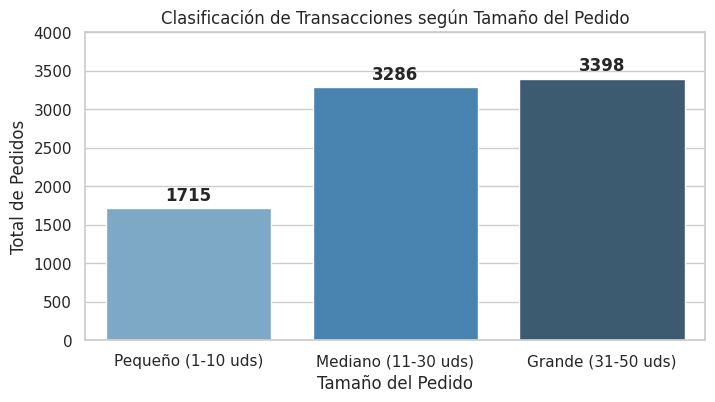

In [13]:
print("\Generando gráficos de negocio con datos limpios")

# Gráfico A: Distribución de Cantidades por Pedido
plt.figure(figsize=(8, 4))
# 1. para crear grupos claros
rangos = pd.cut(
    df["Order Quantity"],
    bins=[0, 10, 30, 50],
    labels=["Pequeño (1-10 uds)", "Mediano (11-30 uds)", "Grande (31-50 uds)"]
)

# 2. Se Dibuja un gráfico de barras separado y con colores distintos
ax = sns.countplot(x=rangos, hue=rangos, palette="Blues_d", legend=False)

# 3. Se agrega el número exacto encima de cada barra para lectura rápida
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%d", padding=3, fontweight="bold")

plt.title("Clasificación de Transacciones según Tamaño del Pedido")
plt.xlabel("Tamaño del Pedido")
plt.ylabel("Total de Pedidos")
plt.ylim(0, 4000) # Damos espacio arriba para que no se corte el número
plt.show()


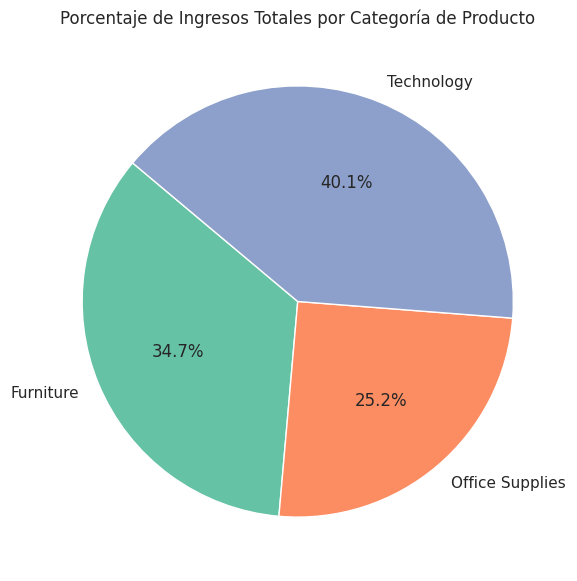

In [11]:
# Gráfico B: Rango de Ventas Financieras por Categoría
plt.figure(figsize=(7, 7))
# 1. Se agrupa por categoría y se suma el total de dinero vendido en cada una
ventas_por_categoria = df.groupby("Product Category")["Sales"].sum() #Agrupa todas las filas que pertenecen a la misma categoría y suma sus ventas totales en tres grandes cifras.
# 2. Se Dibuja el pastel con porcentajes automáticos (autopct) y colores suaves
plt.pie(
  ventas_por_categoria,
  labels=ventas_por_categoria.index,
  autopct="%1.1f%%", #Calcula automáticamente el porcentaje que representa cada porción y lo escribe dentro del gráfico con un decimal
  startangle=140, #Gira el círculo para que los textos y porcentajes queden bien acomodados y no se choquen entre sí.
  colors=sns.color_palette("Set2"),
)
plt.title("Porcentaje de Ingresos Totales por Categoría de Producto")
plt.show()